In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/AmesHousing.csv", sep="\t")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
numeric_df = df.select_dtypes(include="number").drop(
    columns=["Order", "PID"],
    errors="ignore"
)

correlations = numeric_df.corr()["SalePrice"].drop("SalePrice")

correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

display(correlations.to_frame(name="Correlation with SalePrice").round(3))

,Correlation with SalePrice
Overall Qual,0.799
Gr Liv Area,0.707
Garage Cars,0.648
Garage Area,0.640
Total Bsmt SF,0.632
1st Flr SF,0.622
Year Built,0.558
Full Bath,0.546
Year Remod/Add,0.533
Garage Yr Blt,0.527


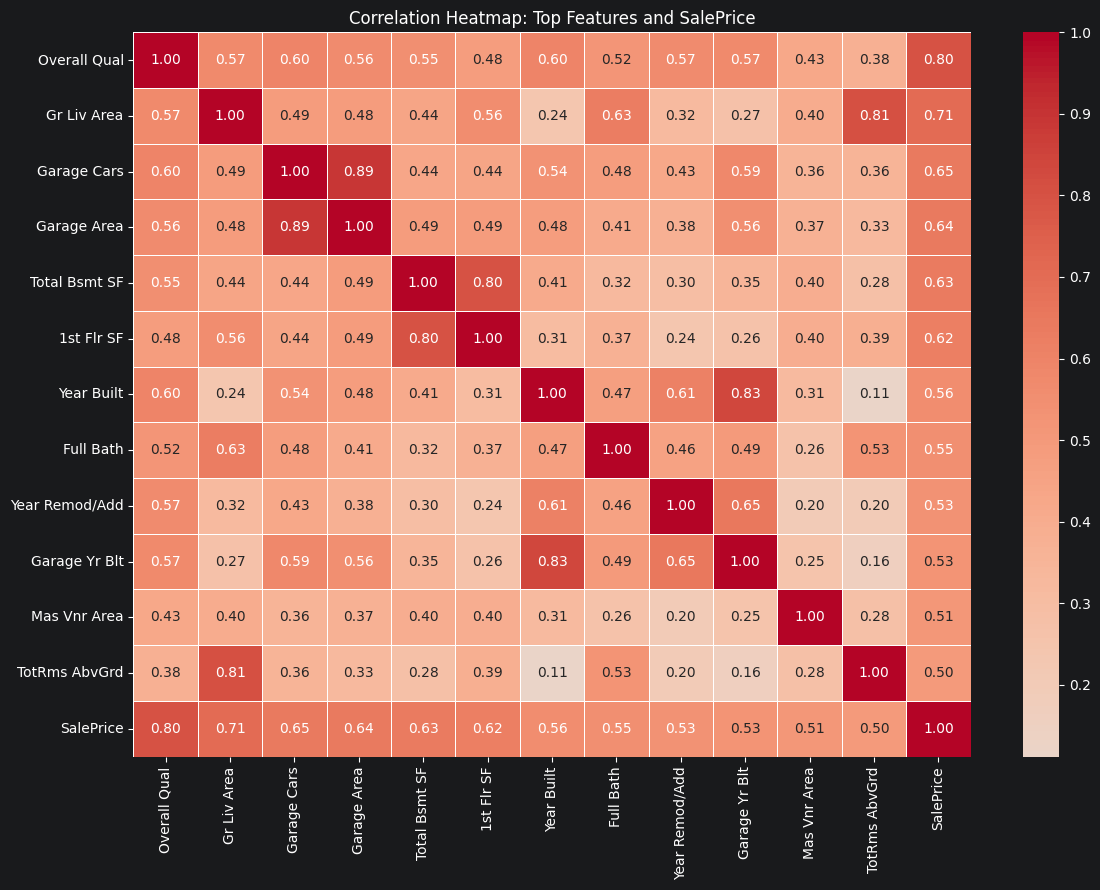

In [5]:
top_features = correlations.head(12).index.tolist()
heatmap_features = top_features + ["SalePrice"]

corr_matrix = numeric_df[heatmap_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap: Top Features and SalePrice")
plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation analysis shows that `Overall Qual` has the strongest positive linear relationship with `SalePrice` (r = 0.799), followed by `Gr Liv Area` (r = 0.707). Other relevant variables include `Garage Cars` (r = 0.648), `Garage Area` (r = 0.640), `Total Bsmt SF` (r = 0.632), and `1st Flr SF` (r = 0.622).

These results suggest that overall quality and house size are particularly relevant when examining sale prices in the Ames Housing dataset. The heatmap also reveals strong correlations between some predictor variables, such as `Garage Cars` and `Garage Area` (r = 0.89), indicating that certain features may contain overlapping information.

Correlation does not imply causation, and these results describe linear relationships only.


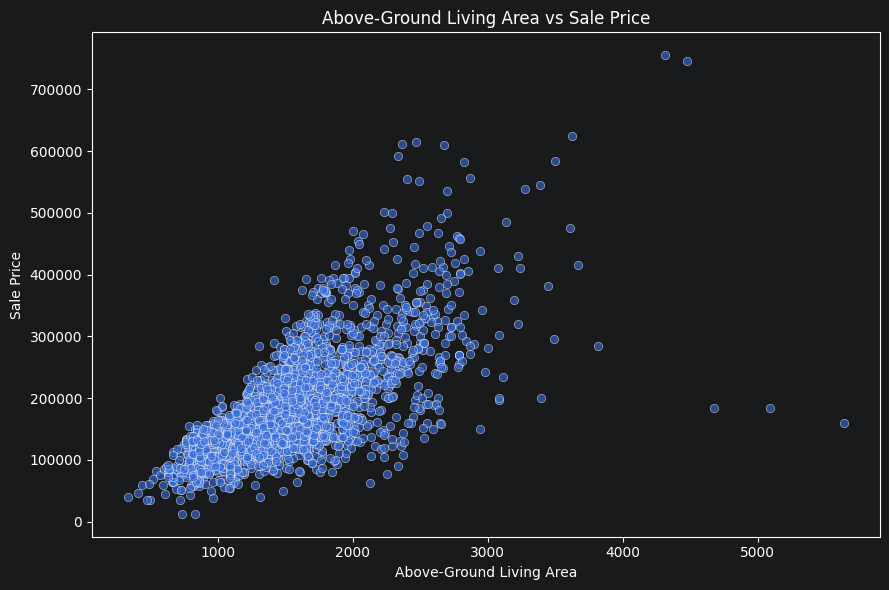

In [8]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Gr Liv Area",
    y="SalePrice",
    alpha=0.6
)

plt.title("Above-Ground Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

In [9]:
display(
    df[df["Gr Liv Area"] > 4000][
        ["PID", "Neighborhood", "Gr Liv Area", "Overall Qual", "SalePrice", "Sale Condition"]
    ].sort_values(by="Gr Liv Area", ascending=False)
)

,PID,Neighborhood,Gr Liv Area,Overall Qual,SalePrice,Sale Condition
1498,908154235,Edwards,5642,10,160000,Partial
2180,908154195,Edwards,5095,10,183850,Partial
2181,908154205,Edwards,4676,10,184750,Partial
1760,528320050,NoRidge,4476,10,745000,Abnorml
1767,528351010,NoRidge,4316,10,755000,Normal


### Relationship: Above-Ground Living Area vs. Sale Price

The scatter plot shows a strong positive linear relationship between `Gr Liv Area` and `SalePrice` ($r = 0.707$). As the above-ground living area increases, the sale price generally increases as well. However, price dispersion widens considerably for larger homes (above 2,500 sq ft), indicating that other factors—such as construction quality and neighborhood—strongly influence the price of larger properties.

Inspecting the five extreme observations with `Gr Liv Area > 4,000` sq ft reveals two distinct cases:
- **Plausible luxury homes:** Two properties with living areas of 4,316 sq ft and 4,476 sq ft (both rated `Overall Qual = 10`) sold for $755,000 and $745,000, following the general upward trend.
- **Anomalous observations:** Three properties with massive living areas (4,676, 5,095, and 5,642 sq ft) sold for unusually low prices ($160,000 to $184,750) despite having `Overall Qual = 10`. All three are recorded with `Sale Condition = Partial`, meaning the homes were likely unfinished when assessed. While we keep them during exploratory analysis, they are prime candidates for removal before fitting linear regression models.

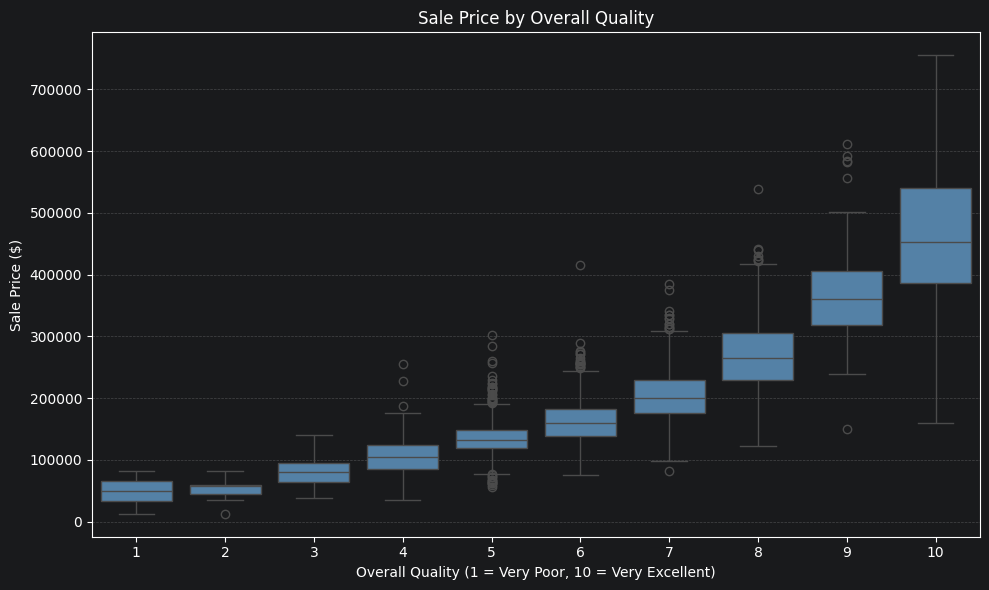

In [10]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Overall Qual",
    y="SalePrice",
    color="steelblue"
)

plt.title("Sale Price by Overall Quality")
plt.xlabel("Overall Quality (1 = Very Poor, 10 = Very Excellent)")
plt.ylabel("Sale Price ($)")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Relationship: Overall Quality vs. Sale Price

The box plot demonstrates a strong, positive, and monotonically increasing relationship between `Overall Qual` and `SalePrice` ($r = 0.799$). Across all quality tiers from 1 to 10, the median sale price consistently shifts upward—rising from $50,150 for quality rating 1 and $133,000 for rating 5 (Average) to $360,000 for rating 9 and $451,950 for rating 10 (Very Excellent).

Two additional patterns stand out:
1. **Non-linear Acceleration:** The price increments between consecutive quality levels become noticeably larger at the upper end of the scale (levels 7 through 10) compared to the lower tiers (levels 1 through 5).
2. **Increasing Price Variability:** Both the interquartile range (IQR) and overall spread expand substantially for higher-quality homes (IQR grows from $28,383 at level 5 to $154,487 at level 10). Furthermore, the long lower whisker at quality level 10 (reaching down to $160,000) is directly explained by the three unfinished (`Partial` sale condition) properties in `Edwards` identified in the living area scatter plot.

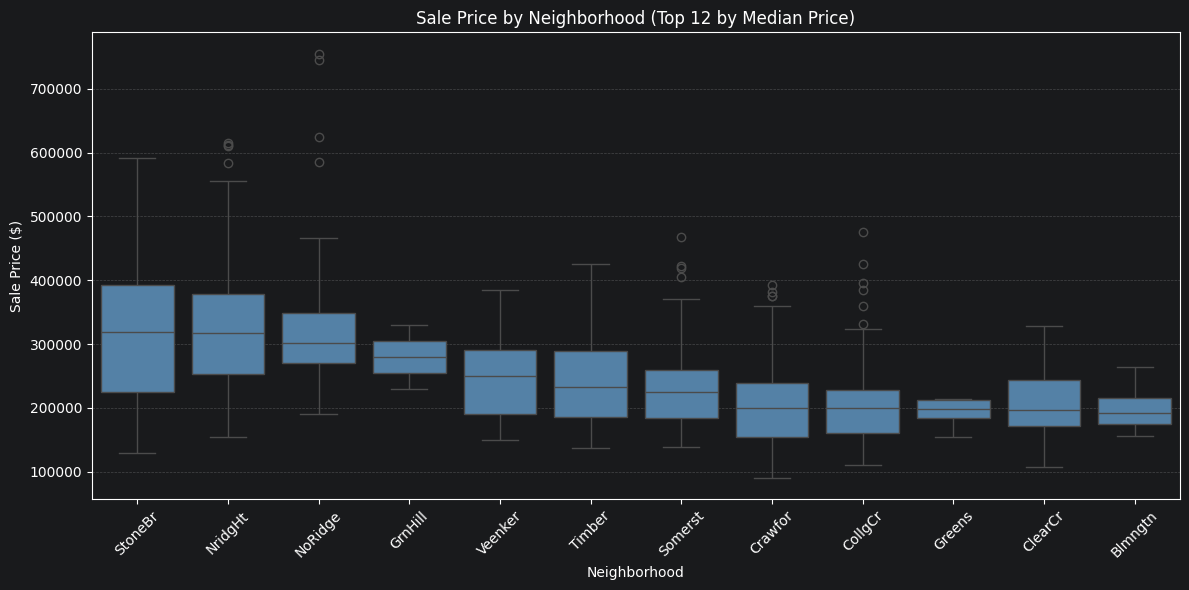

In [11]:
top_neighborhoods = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
    .head(12)
    .index
)

plot_data = df[df["Neighborhood"].isin(top_neighborhoods)]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=plot_data,
    x="Neighborhood",
    y="SalePrice",
    order=top_neighborhoods,
    color="steelblue"
)

plt.title("Sale Price by Neighborhood (Top 12 by Median Price)")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price ($)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Relationship: Neighborhood vs. Sale Price

The box plot comparing the top 12 neighborhoods by median sale price highlights clear geographic stratification in the Ames housing market. Premium neighborhoods such as `StoneBr`, `NridgHt`, and `NoRidge` exhibit the highest median prices (exceeding $300,000) and substantial price variability.

Conversely, other prominent neighborhoods (e.g., `CollgCr`, `Somerst`) display wider interquartile ranges and multiple upper outliers, indicating considerable internal diversity in property values and sizing within the same neighborhood. Smaller sample sizes in specific categories (such as `GrnHill`) should also be taken into account when interpreting local price distributions.

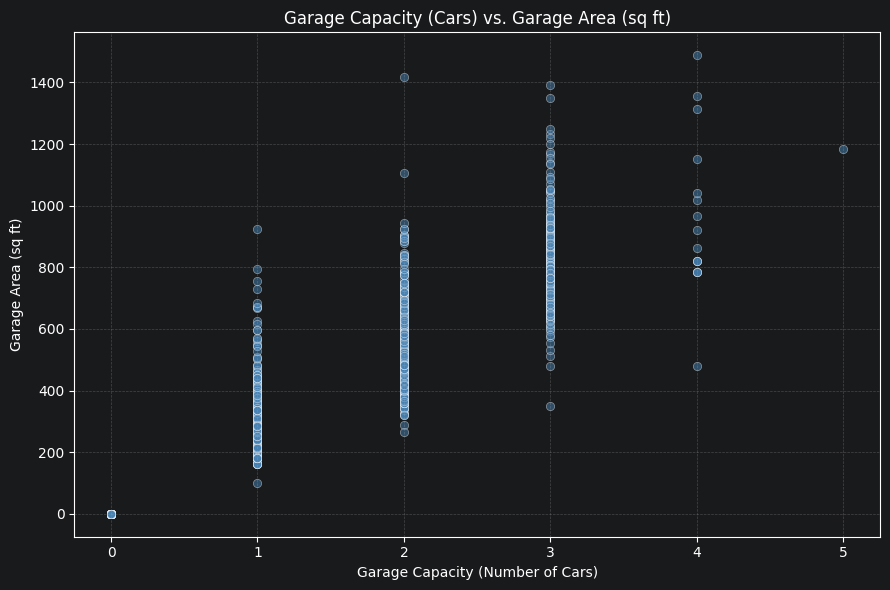

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Garage Cars",
    y="Garage Area",
    alpha=0.5,
    color="steelblue"
)

plt.title("Garage Capacity (Cars) vs. Garage Area (sq ft)")
plt.xlabel("Garage Capacity (Number of Cars)")
plt.ylabel("Garage Area (sq ft)")
plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Relationship: Garage Capacity (Cars) vs. Garage Area

The scatter plot displays a strong positive association ($r = 0.89$) between `Garage Cars` (discrete capacity) and `Garage Area` (continuous square footage). As expected, properties with higher car capacities consistently feature larger garage areas.

Most homes are concentrated around 1- to 3-car capacities, with 2-car garages being the most common typology. Because both features describe the physical size and accommodation capacity of the garage, they contain highly overlapping information. This redundancy is an important consideration for feature selection, as retaining both in a linear model can lead to multicollinearity.

### Feature Selection Proposals

Pe baza analizei corelațiilor și a distribuțiilor vizuale, propunem următoarele decizii preliminare de selecție a variabilelor pentru o viitoare modelare:

| Feature | Propunere | Motiv |
| :--- | :--- | :--- |
| **PID** | Candidat pentru eliminare | Este un identificator administrativ al parcelei, fără valoare predictivă pentru prețul casei. |
| **Order** | Candidat pentru eliminare | Reprezintă doar numărul rândului în setul de date. |
| **Overall Qual** | Păstrare | Este cel mai puternic predictor liniar pentru `SalePrice` ($r = 0.799$). |
| **Gr Liv Area** | Păstrare | Măsoară spațiul locuibil principal și are o asociere puternică cu prețul ($r = 0.707$). |
| **Garage Area / Garage Cars** | Păstrare doar a uneia | Așa cum a arătat scatter plot-ul anterior, conțin informații puternic redundante ($r = 0.89$). Într-un model de regresie, păstrarea ambelor ar introduce multicoliniaritate. |
| **Year Built / Garage Yr Blt** | Candidat eliminare `Garage Yr Blt` | Sunt puternic corelate ($r = 0.83$). În plus, `Garage Yr Blt` are valori lipsă pentru casele fără garaj, în timp ce `Year Built` este complet și oferă informația principală despre vechimea proprietății. |
| **SalePrice** | Păstrare ca Țintă (Target) | Este variabila dependentă. Într-un model viitor, nu trebuie inclusă printre predictorii folosiți (pentru a evita target leakage). |

### Feature Engineering

Pentru a extrage informații mai utile și mai ușor de interpretat decât datele brute, construim trei caracteristici (features) noi:
1. **House Age at Sale:** Vechimea casei la momentul vânzării. Este mai relevantă pentru preț decât anul construcției în sine.
2. **Years Since Remodel:** Numărul de ani de la ultima renovare până la momentul tranzacției. Reflectă starea actualizată a finisajelor.
3. **Total Living Space:** Suprafața combinată a spațiilor (deasupra solului + subsolul total). Oferă o perspectivă asupra amprentei masive a casei (chiar dacă subsolul nu este 100% finisat).

In [13]:
df["House Age at Sale"] = df["Yr Sold"] - df["Year Built"]

df["Years Since Remodel"] = df["Yr Sold"] - df["Year Remod/Add"]

df["Total Living Space"] = df["Gr Liv Area"] + df["Total Bsmt SF"].fillna(0)

cols_to_show = [
    "Year Built", "Year Remod/Add", "Yr Sold",
    "House Age at Sale", "Years Since Remodel",
    "Gr Liv Area", "Total Bsmt SF", "Total Living Space"
]

display(df[cols_to_show].head())

print("\nCorelațiile noilor features cu SalePrice:")
display(df[["House Age at Sale", "Years Since Remodel", "Total Living Space", "SalePrice"]].corr()["SalePrice"].round(3))

,Year Built,Year Remod/Add,Yr Sold,House Age at Sale,Years Since Remodel,Gr Liv Area,Total Bsmt SF,Total Living Space
0,1960,1960,2010,50,50,1656,1080.0,2736.0
1,1961,1961,2010,49,49,896,882.0,1778.0
2,1958,1958,2010,52,52,1329,1329.0,2658.0
3,1968,1968,2010,42,42,2110,2110.0,4220.0
4,1997,1998,2010,13,12,1629,928.0,2557.0



Corelațiile noilor features cu SalePrice:


House Age at Sale     -0.559
Years Since Remodel   -0.535
Total Living Space     0.790
SalePrice              1.000
Name: SalePrice, dtype: float64

### External Data Proposals

Deși setul de date Ames Housing este foarte detaliat în privința caracteristicilor fizice ale locuințelor, analiza și modelele predictive ar putea fi îmbunătățite semnificativ prin integrarea unor surse de date externe:

| Date externe | Motivul utilității |
| :--- | :--- |
| **Indicatori macroeconomici (Dobânzi, Inflație)** | Datele acoperă perioada 2006–2010, incluzând criza imobiliară. Ratele dobânzilor ipotecare și inflația la momentul vânzării ar contextualiza fluctuațiile prețurilor. |
| **Distanța față de puncte de interes (GIS)** | Coordonatele geospațiale ar permite calcularea distanței față de Iowa State University, centrul orașului sau parcuri, facilități care cresc valoarea proprietății. |
| **Calitatea școlilor (School District Ratings)** | Ratingurile școlilor publice arondate fiecărui cartier reprezintă adesea un factor decizional major pentru cumpărători și influențează direct prețul. |
| **Date privind criminalitatea** | Rata criminalității la nivel de cartier ar ajuta la evaluarea siguranței, care este invers corelată, în general, cu prețul imobiliarelor. |

**Integrare:** Pentru a folosi aceste date, am avea nevoie de o cheie de legătură geografică (geocodarea adreselor pe baza `PID` sau folosirea numelui cartierului) și de o cheie temporală (`Yr Sold` și `Mo Sold`) pentru a alinia datele economice cu momentul tranzacției.

### Conclusions: Relationships & Feature Engineering

În urma analizei exploratorii a relațiilor dintre variabile (EDA) și a procesului de feature engineering, am desprins următoarele concluzii principale:

1. **Predictorii principali:** Calitatea generală a construcției (`Overall Qual`, $r = 0.799$) și suprafața locuibilă (`Gr Liv Area`, $r = 0.707$) sunt factorii care influențează cel mai puternic prețul de vânzare. Relația prețului cu calitatea este neliniară, accelerând vizibil la nivelurile superioare (8–10).
2. **Impactul cartierului:** Există o stratificare clară a prețurilor în funcție de locație. Cartierele premium (`StoneBr`, `NridgHt`, `NoRidge`) au mediane de peste 300.000$, comparativ cu mediana globală de aproximativ 160.000$, demonstrând că locația justifică o mare parte din variația prețului.
3. **Calitatea datelor și Outlieri:** Analiza vizuală a evidențiat outlieri extremi (ex. 3 case de peste 4.600 sq ft vândute sub 200.000$). Verificările au demonstrat că acestea nu sunt erori de introducere a datelor, ci vânzări atipice (locuințe neterminate, `Sale Condition = Partial`), care trebuie tratate distinct în modelare.
4. **Multicoliniaritate:** S-a confirmat o redundanță ridicată între anumiți predictori (ex. `Garage Cars` și `Garage Area` cu $r = 0.89$), subliniind necesitatea unei selecții atente a variabilelor (Feature Selection) pentru modelele liniare.
5. **Feature Engineering de succes:** Construirea variabilei `Total Living Space` (combinând suprafața deasupra solului cu subsolul) a generat un predictor extrem de puternic ($r = 0.790$ cu ținta), demonstrând utilitatea derivării de noi caracteristici din datele brute.